<a href="https://colab.research.google.com/github/Freddykaseya/groupe-03-IADS/blob/main/notebooks/Credit_Card_Fraud_Detection_Group03.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Credit Card Fraud Detection

## Group 03

### Research Objective
Detect fraudulent credit card transactions using
machine learning algorithms.

### Models
- Logistic Regression
- Random Forest
- Isolation Forest

### Evaluation Metrics
- Precision
- Recall
- F1-score
- PR-AUC

In [2]:
# ==========================================
# 1. IMPORTATION DES BIBLIOTHÈQUES
# ==========================================

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import sklearn

from pathlib import Path
import warnings

warnings.filterwarnings("ignore")

# Reproductibilité
RANDOM_STATE = 42

# Configuration d'affichage
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

sns.set_theme(style="whitegrid")

print("Environnement initialisé avec succès.")
print("Pandas :", pd.__version__)
print("NumPy :", np.__version__)
print("Scikit-learn :", sklearn.__version__)

Environnement initialisé avec succès.
Pandas : 2.2.3
NumPy : 2.4.6
Scikit-learn : 1.6.1


In [3]:
# Installation  kaggle
%pip install -q -U kagglehub

In [4]:
import os
import kagglehub
from google.colab import userdata
from pathlib import Path

# Récupération sécurisée du token
os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")

# Identifiant Kaggle du dataset
DATASET_ID = "mlg-ulb/creditcardfraud"

# Téléchargement
dataset_path = kagglehub.dataset_download(
    DATASET_ID,
    output_dir="/content/credit_card_fraud"
)

print("Dataset téléchargé :", dataset_path)

Using Colab cache for faster access to the 'creditcardfraud' dataset.
Dataset téléchargé : /kaggle/input/creditcardfraud


In [5]:
# Rechercher le fichier CSV téléchargé
csv_files = list(Path(dataset_path).rglob("creditcard.csv"))

if not csv_files:
    raise FileNotFoundError("creditcard.csv introuvable.")

DATA_PATH = csv_files[0]

# Chargement
df = pd.read_csv(DATA_PATH)

print("Dataset chargé avec succès.")
print("Dimensions :", df.shape)

Dataset chargé avec succès.
Dimensions : (284807, 31)


# A savoir sur  les  données  

Les  valeurs  écrites  dans ce tableau répresente de transaction, qui sont   représentées  par  des caractéristiques obtenues par une transformation mathématique appelée PCA (Principal Component Analysis), ou analyse en composantes principales.
> Ajouter une citation



In [14]:
df.head()


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,0.090794,-0.551600,-0.617801,-0.991390,-0.311169,1.468177,-0.470401,0.207971,0.025791,0.403993,0.251412,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,-0.166974,1.612727,1.065235,0.489095,-0.143772,0.635558,0.463917,-0.114805,-0.183361,-0.145783,-0.069083,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,0.207643,0.624501,0.066084,0.717293,-0.165946,2.345865,-2.890083,1.109969,-0.121359,-2.261857,0.524980,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,-0.054952,-0.226487,0.178228,0.507757,-0.287924,-0.631418,-1.059647,-0.684093,1.965775,-1.232622,-0.208038,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,0.753074,-0.822843,0.538196,1.345852,-1.119670,0.175121,-0.451449,-0.237033,-0.038195,0.803487,0.408542,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [7]:
# ==========================================
# 2. PREMIER DIAGNOSTIC DU DATASET
# ==========================================

print("DIMENSIONS DU DATASET")
print(df.shape)

print("\nNOMS DES COLONNES")
print(df.columns.tolist())

print("\nTYPES DES VARIABLES")
print(df.dtypes)

print("\nINFORMATIONS GÉNÉRALES")
df.info()

print("\nSTATISTIQUES DESCRIPTIVES")
display(df.describe())

print("\nDISTRIBUTION DE LA VARIABLE CIBLE")
display(df["Class"].value_counts())

print("\nPROPORTION DE CHAQUE CLASSE")
display(df["Class"].value_counts(normalize=True) * 100)

DIMENSIONS DU DATASET
(284807, 31)

NOMS DES COLONNES
['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Class']

TYPES DES VARIABLES
Time      float64
V1        float64
V2        float64
V3        float64
V4        float64
V5        float64
V6        float64
V7        float64
V8        float64
V9        float64
V10       float64
V11       float64
V12       float64
V13       float64
V14       float64
V15       float64
V16       float64
V17       float64
V18       float64
V19       float64
V20       float64
V21       float64
V22       float64
V23       float64
V24       float64
V25       float64
V26       float64
V27       float64
V28       float64
Amount    float64
Class       int64
dtype: object

INFORMATIONS GÉNÉRALES
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 # 

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,284807.000000,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,284807.000000,284807.000000
mean,94813.859575,1.175161e-15,3.384974e-16,-1.379537e-15,2.094852e-15,1.021879e-15,1.494498e-15,-5.620335e-16,1.149614e-16,-2.414189e-15,2.238554e-15,1.724421e-15,-1.245415e-15,8.238900e-16,1.213481e-15,4.866699e-15,1.436219e-15,-3.768179e-16,9.707851e-16,1.036249e-15,6.418678e-16,1.628620e-16,-3.576577e-16,2.618565e-16,4.473914e-15,5.109395e-16,1.686100e-15,-3.661401e-16,-1.227452e-16,88.349619,0.001727
std,47488.145955,1.958696e+00,1.651309e+00,1.516255e+00,1.415869e+00,1.380247e+00,1.332271e+00,1.237094e+00,1.194353e+00,1.098632e+00,1.088850e+00,1.020713e+00,9.992014e-01,9.952742e-01,9.585956e-01,9.153160e-01,8.762529e-01,8.493371e-01,8.381762e-01,8.140405e-01,7.709250e-01,7.345240e-01,7.257016e-01,6.244603e-01,6.056471e-01,5.212781e-01,4.822270e-01,4.036325e-01,3.300833e-01,250.120109,0.041527
min,0.000000,-5.640751e+01,-7.271573e+01,-4.832559e+01,-5.683171e+00,-1.137433e+02,-2.616051e+01,-4.355724e+01,-7.321672e+01,-1.343407e+01,-2.458826e+01,-4.797473e+00,-1.868371e+01,-5.791881e+00,-1.921433e+01,-4.498945e+00,-1.412985e+01,-2.516280e+01,-9.498746e+00,-7.213527e+00,-5.449772e+01,-3.483038e+01,-1.093314e+01,-4.480774e+01,-2.836627e+00,-1.029540e+01,-2.604551e+00,-2.256568e+01,-1.543008e+01,0.000000,0.000000
25%,54201.500000,-9.203734e-01,-5.985499e-01,-8.903648e-01,-8.486401e-01,-6.915971e-01,-7.682956e-01,-5.540759e-01,-2.086297e-01,-6.430976e-01,-5.354257e-01,-7.624942e-01,-4.055715e-01,-6.485393e-01,-4.255740e-01,-5.828843e-01,-4.680368e-01,-4.837483e-01,-4.988498e-01,-4.562989e-01,-2.117214e-01,-2.283949e-01,-5.423504e-01,-1.618463e-01,-3.545861e-01,-3.171451e-01,-3.269839e-01,-7.083953e-02,-5.295979e-02,5.600000,0.000000
50%,84692.000000,1.810880e-02,6.548556e-02,1.798463e-01,-1.984653e-02,-5.433583e-02,-2.741871e-01,4.010308e-02,2.235804e-02,-5.142873e-02,-9.291738e-02,-3.275735e-02,1.400326e-01,-1.356806e-02,5.060132e-02,4.807155e-02,6.641332e-02,-6.567575e-02,-3.636312e-03,3.734823e-03,-6.248109e-02,-2.945017e-02,6.781943e-03,-1.119293e-02,4.097606e-02,1.659350e-02,-5.213911e-02,1.342146e-03,1.124383e-02,22.000000,0.000000
75%,139320.500000,1.315642e+00,8.037239e-01,1.027196e+00,7.433413e-01,6.119264e-01,3.985649e-01,5.704361e-01,3.273459e-01,5.971390e-01,4.539234e-01,7.395934e-01,6.182380e-01,6.625050e-01,4.931498e-01,6.488208e-01,5.232963e-01,3.996750e-01,5.008067e-01,4.589494e-01,1.330408e-01,1.863772e-01,5.285536e-01,1.476421e-01,4.395266e-01,3.507156e-01,2.409522e-01,9.104512e-02,7.827995e-02,77.165000,0.000000
max,172792.000000,2.454930e+00,2.205773e+01,9.382558e+00,1.687534e+01,3.480167e+01,7.330163e+01,1.205895e+02,2.000721e+01,1.559499e+01,2.374514e+01,1.201891e+01,7.848392e+00,7.126883e+00,1.052677e+01,8.877742e+00,1.731511e+01,9.253526e+00,5.041069e+00,5.591971e+00,3.942090e+01,2.720284e+01,1.050309e+01,2.252841e+01,4.584549e+00,7.519589e+00,3.517346e+00,3.161220e+01,3.384781e+01,25691.160000,1.000000



DISTRIBUTION DE LA VARIABLE CIBLE


,count
Class,
0,284315
1,492



PROPORTION DE CHAQUE CLASSE


,proportion
Class,
0,99.827251
1,0.172749


## vérification de la qualité de la DATA

In [8]:
# ==========================================
# 3. DIAGNOSTIC DE LA QUALITÉ DES DONNÉES
# ==========================================

# 1. Valeurs manquantes
print("VALEURS MANQUANTES")
missing_values = df.isnull().sum()

display(
    missing_values[missing_values > 0]
)

print(
    "Total des valeurs manquantes :",
    df.isnull().sum().sum()
)


# 2. Doublons
print("\nDOUBLONS")

duplicate_count = df.duplicated().sum()

print("Nombre de doublons :", duplicate_count)


# 3. Nombre de valeurs uniques par colonne
print("\nVALEURS UNIQUES")

unique_values = df.nunique().sort_values(
    ascending=False
)

display(unique_values)


# 4. Vérification de la variable cible
print("\nVALIDATION DE LA CIBLE")

print("Valeurs présentes :", df["Class"].unique())

print("Nombre de classes :", df["Class"].nunique())


# 5. Vérification des valeurs infinies
print("\nVALEURS INFINIES")

infinite_count = np.isinf(
    df.select_dtypes(include=np.number)
).sum().sum()

print("Nombre de valeurs infinies :", infinite_count)

VALEURS MANQUANTES


,0


Total des valeurs manquantes : 0

DOUBLONS
Nombre de doublons : 1081

VALEURS UNIQUES


,0
V1,275663
V2,275663
V3,275663
V5,275663
V4,275663
V6,275663
V7,275663
V11,275663
V8,275663
V9,275663



VALIDATION DE LA CIBLE
Valeurs présentes : [0 1]
Nombre de classes : 2

VALEURS INFINIES
Nombre de valeurs infinies : 0


## 3. Diagnostic initial de la qualité des données

Cette première analyse vise à identifier les éventuels problèmes de qualité présents dans notre jeu de données avant toute opération de nettoyage.

### 3.1 Valeurs manquantes

Aucune valeur manquante n'a été détectée dans les 31 colonnes du dataset.

**Décision :** aucune opération de remplacement ou de suppression liée aux valeurs manquantes n'est nécessaire à ce stade.

### 3.2 Doublons

L'analyse initiale a permis de détecter 1 081 lignes dupliquées.

**Décision :** aucune suppression n'est effectuée pour le moment. Une analyse complémentaire est nécessaire afin d'étudier leur répartition entre les transactions normales et frauduleuses.

### 3.3 Valeurs infinies

Aucune valeur infinie n'a été détectée dans les variables numériques.

**Décision :** aucune correction n'est nécessaire pour ce problème.

### 3.4 Variable cible

La variable cible `Class` contient deux catégories :

- 0 : transaction normale.
- 1 : transaction frauduleuse.

Le dataset présente un fort déséquilibre entre ces deux catégories, les transactions frauduleuses représentant environ 0,173 % des observations.

### 3.5 Conclusion provisoire

Le dataset ne présente aucune valeur manquante ni valeur infinie. Toutefois, la présence de 1 081 doublons nécessite une investigation complémentaire avant de décider d'une éventuelle suppression.

Le déséquilibre important de la variable cible constitue également un élément central à prendre en compte dans le choix des méthodes et des métriques d'évaluation.

In [9]:
# ==========================================
# 5. ANALYSE APPROFONDIE DES DOUBLONS
# ==========================================

# Identifier toutes les lignes appartenant
# à un groupe de doublons
duplicate_rows = df[
    df.duplicated(keep=False)
].copy()

print("Nombre de lignes appartenant à des groupes de doublons :",
      len(duplicate_rows))

# Répartition des lignes dupliquées selon Class
print("\nRépartition des doublons selon la cible :")

display(
    duplicate_rows["Class"].value_counts()
)

# Pourcentages
print("\nPourcentage par classe :")

display(
    duplicate_rows["Class"]
    .value_counts(normalize=True) * 100
)

# Comparaison avec le dataset complet
print("\nRépartition de la cible dans le dataset complet :")

display(
    df["Class"].value_counts()
)

Nombre de lignes appartenant à des groupes de doublons : 1854

Répartition des doublons selon la cible :


,count
Class,
0,1822
1,32



Pourcentage par classe :


,proportion
Class,
0,98.274002
1,1.725998



Répartition de la cible dans le dataset complet :


,count
Class,
0,284315
1,492


In [10]:
# Identifier les lignes appartenant à des groupes de doublons
duplicate_rows = df[df.duplicated(keep=False)].copy()

# Compter le nombre d'occurrences de chaque ligne identique
duplicate_groups = (
    duplicate_rows
    .groupby(list(df.columns), dropna=False)
    .size()
    .reset_index(name="nombre_occurrences")
)

print("Nombre de groupes de doublons :", len(duplicate_groups))

print("\nDistribution du nombre d'occurrences :")
display(duplicate_groups["nombre_occurrences"].value_counts().sort_index())

print("\nNombre de groupes de doublons par classe :")
display(duplicate_groups.groupby("Class").size())

print("\nExemples de groupes de doublons :")
display(duplicate_groups.head(10))

Nombre de groupes de doublons : 773

Distribution du nombre d'occurrences :


,count
nombre_occurrences,
2,611
3,66
4,81
5,10
6,1
9,2
18,2



Nombre de groupes de doublons par classe :


,0
Class,
0,760
1,13



Exemples de groupes de doublons :


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class,nombre_occurrences
0,26.0,-0.535388,0.865268,1.351076,0.147575,0.433680,0.086983,0.693039,0.179742,-0.285642,-0.482474,0.871800,0.853447,-0.571822,0.102252,-1.519991,-0.285912,-0.309633,-0.403902,-0.823743,-0.283264,0.049526,0.206537,-0.187108,0.000753,0.098117,-0.553471,-0.078306,0.025427,1.77,0,2
1,26.0,-0.529912,0.873892,1.347247,0.145457,0.414209,0.100223,0.711206,0.176066,-0.286717,-0.484688,0.872490,0.851636,-0.571745,0.100974,-1.519772,-0.284376,-0.310524,-0.404248,-0.823374,-0.290348,0.046949,0.208105,-0.185548,0.001031,0.098816,-0.552904,-0.073288,0.023307,6.14,0,2
2,74.0,1.038370,0.127486,0.184456,1.109950,0.441699,0.945283,-0.036715,0.350995,0.118950,-0.243289,0.578063,0.674730,-0.534231,0.446601,1.122885,-1.768001,1.241157,-2.449500,-1.747255,-0.335520,0.102520,0.605089,0.023092,-0.626463,0.479120,-0.166937,0.081247,0.001192,1.18,0,4
3,145.0,-2.420413,1.947885,0.553646,0.983069,-0.281518,2.408958,-1.401613,-0.188299,0.675878,0.158497,-1.224951,1.314705,0.304412,-0.290218,-2.014548,-0.772801,0.696761,0.017914,2.177250,-0.276207,1.213826,-1.238620,0.006927,-1.724222,0.239603,-0.313703,-0.188281,0.119831,6.00,0,2
4,145.0,-2.419486,1.949346,0.552998,0.982710,-0.284815,2.411200,-1.398537,-0.188922,0.675695,0.158123,-1.224834,1.314398,0.304425,-0.290434,-2.014511,-0.772540,0.696610,0.017855,2.177312,-0.277406,1.213390,-1.238354,0.007191,-1.724175,0.239721,-0.313607,-0.187431,0.119472,6.74,0,2
5,919.0,0.904289,-0.538055,0.396058,0.500680,-0.864473,-0.657199,0.027231,-0.029473,0.265447,-0.110991,1.254250,0.704631,-0.967461,0.466524,-0.303979,0.094702,-0.198326,-0.124616,0.401377,0.157346,-0.099460,-0.597579,-0.048666,0.551824,0.182934,0.402176,-0.081357,0.027252,158.00,0,2
6,919.0,1.207596,-0.036860,0.572104,0.373148,-0.709633,-0.713698,-0.181105,0.011277,0.283940,-0.037866,1.252000,0.698164,-0.995452,0.430980,-0.323729,0.073995,-0.202981,-0.156783,0.451522,-0.162378,-0.194591,-0.514717,0.089714,0.543768,0.240581,0.418921,-0.051693,-0.000085,1.00,0,2
7,1074.0,-2.445204,-0.505494,0.164511,-0.449658,0.460784,-0.509035,-0.490478,1.060597,-0.385591,-1.053488,-0.553817,0.207330,-0.933946,0.969621,-0.758698,0.863809,-0.533855,0.559857,0.502850,0.171937,0.060361,-0.802101,-0.299229,-0.831608,-0.055518,0.315454,-0.467257,-0.167591,1.00,0,2
8,1074.0,-2.248488,-0.195670,0.026949,-0.525780,-0.238759,-0.033359,0.162196,0.928520,-0.424215,-1.133001,-0.529027,0.142246,-0.931195,0.923712,-0.750816,0.919012,-0.565837,0.547431,0.516124,-0.082562,-0.032208,-0.745757,-0.243193,-0.821633,-0.030402,0.335838,-0.286998,-0.243768,158.00,0,2
9,1308.0,-1.379848,0.536720,2.647870,1.408111,0.126442,0.986525,0.960251,-0.629717,1.729173,1.346832,-0.622458,0.516210,0.174168,-2.023273,-1.185043,-2.036791,0.653358,-1.294348,1.297445,0.464675,-0.666874,-0.343574,0.022138,0.093532,0.011293,-0.503395,-0.438189,-0.346731,43.80,0,2


In [11]:
# Examiner uniquement les groupes de doublons frauduleux

fraud_duplicate_groups = duplicate_groups[
    duplicate_groups["Class"] == 1
].copy()

print("Nombre de groupes de doublons frauduleux :",
      len(fraud_duplicate_groups))

print("\nNombre total d'occurrences dans ces groupes :",
      fraud_duplicate_groups["nombre_occurrences"].sum())

print("\nDistribution de leurs occurrences :")
display(
    fraud_duplicate_groups["nombre_occurrences"]
    .value_counts()
    .sort_index()
)

print("\nDétail des groupes frauduleux :")
display(fraud_duplicate_groups)

Nombre de groupes de doublons frauduleux : 13

Nombre total d'occurrences dans ces groupes : 32

Distribution de leurs occurrences :


,count
nombre_occurrences,
2,11
4,1
6,1



Détail des groupes frauduleux :


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class,nombre_occurrences
281,68207.0,-13.192671,12.785971,-9.906650,3.320337,-4.801176,5.760059,-18.750889,-37.353443,-0.391540,-5.052502,4.406806,-4.610756,-1.909488,-9.072711,-0.226074,-6.211557,-6.248145,-3.149247,0.051576,-3.493050,27.202839,-8.887017,5.303607,-0.639435,0.263203,-0.108877,1.269566,0.939407,1.00,1,6
393,84204.0,-1.927453,1.827621,-7.019495,5.348303,-2.739188,-2.107219,-5.015848,1.205868,-4.382713,-8.337707,7.190306,-9.424844,-0.223293,-12.875494,-0.071918,-6.299961,-12.719207,-3.740176,0.844060,2.172709,1.376938,-0.792017,-0.771414,-0.379574,0.718717,1.111151,1.277707,0.819081,512.25,1,2
394,84204.0,-0.937843,3.462889,-6.445104,4.932199,-2.233983,-2.291561,-5.695594,1.338825,-4.322377,-8.099119,7.182967,-9.445943,-0.314620,-12.991466,-0.136359,-6.367524,-12.734394,-3.845130,1.007667,1.129532,1.066550,-0.521657,-0.319917,-0.405859,0.906802,1.165784,1.374495,0.729889,0.00,1,2
398,85285.0,-7.030308,3.421991,-9.525072,5.270891,-4.024630,-2.865682,-6.989195,3.791551,-4.622730,-8.409665,6.309044,-8.576761,0.246747,-11.534046,-0.364265,-5.452495,-11.887570,-3.563585,0.876019,0.545698,1.103398,-0.541855,0.036943,-0.355519,0.353634,1.042458,1.359516,-0.272188,0.00,1,2
399,85285.0,-6.713407,3.921104,-9.746678,5.148263,-5.151563,-2.099389,-5.937767,3.578780,-4.684952,-8.537758,6.348979,-8.681609,0.251179,-11.608002,-0.351569,-5.363566,-11.939092,-3.583603,0.897402,0.135711,0.954272,-0.451086,0.127214,-0.339450,0.394096,1.075295,1.649906,-0.394905,252.92,1,2
429,93853.0,-6.185857,7.102985,-13.030455,8.010823,-7.885237,-3.974550,-12.229608,4.971232,-4.248307,-12.965481,8.688308,-17.182918,0.069577,-14.116156,0.959032,-12.375334,-18.716765,-6.522015,3.517955,0.483930,2.502772,0.481691,0.480958,0.360319,-0.293354,-0.199193,-0.203917,0.398927,44.90,1,2
430,93853.0,-5.839192,7.151532,-12.816760,7.031115,-9.651272,-2.938427,-11.543207,4.843627,-3.494276,-13.320789,8.460244,-17.003289,0.101557,-14.094452,0.747031,-12.661696,-18.912494,-6.626975,4.008921,0.055684,2.462056,1.054865,0.530481,0.472670,-0.275998,0.282435,0.104886,0.254417,316.06,1,2
431,93860.0,-10.850282,6.727466,-16.760583,8.425832,-10.252697,-4.192171,-14.077086,7.168288,-3.683242,-15.239962,8.030708,-16.060306,0.270530,-14.952981,-0.241095,-11.866731,-15.486990,-5.748652,4.130031,-0.646818,2.541637,0.135535,-1.023967,0.406265,0.106593,-0.026232,-1.464630,-0.411682,78.00,1,2
432,93860.0,-10.632375,7.251936,-17.681072,8.204144,-10.166591,-4.510344,-12.981606,6.783589,-4.659330,-14.924655,8.389142,-16.465504,0.338517,-14.224404,0.556584,-11.683998,-15.841616,-5.753200,3.813041,-0.810146,2.715357,0.695603,-1.138122,0.459442,0.386337,0.522438,-1.416604,-0.488307,188.52,1,2
433,93879.0,-13.086519,7.352148,-18.256576,10.648505,-11.731476,-3.659167,-14.873658,8.810473,-5.418204,-13.202577,6.357227,-15.531611,0.659695,-11.412330,-2.447576,-9.833743,-18.174617,-7.269905,0.623797,-1.376298,2.761157,-0.266162,-0.412861,0.519952,-0.743909,-0.167808,-2.498300,-0.711066,30.31,1,2


In [12]:
# Conserver une copie du dataset original
df_original = df.copy()

# Supprimer les doublons exacts en conservant la première occurrence
df_clean = df.drop_duplicates(keep="first").copy()

# Comparer les dimensions avant et après nettoyage
print("AVANT NETTOYAGE :", df_original.shape)
print("APRÈS NETTOYAGE :", df_clean.shape)

print("\nNombre de lignes supprimées :",
      len(df_original) - len(df_clean))

print("\nRépartition des classes avant nettoyage :")
display(df_original["Class"].value_counts())

print("\nRépartition des classes après nettoyage :")
display(df_clean["Class"].value_counts())

print("\nVérification des doublons restants :",
      df_clean.duplicated().sum())

AVANT NETTOYAGE : (284807, 31)
APRÈS NETTOYAGE : (283726, 31)

Nombre de lignes supprimées : 1081

Répartition des classes avant nettoyage :


,count
Class,
0,284315
1,492



Répartition des classes après nettoyage :


,count
Class,
0,283253
1,473



Vérification des doublons restants : 0


## 4. Traitement des doublons

L'analyse de la qualité des données a révélé 1 081 occurrences supplémentaires
correspondant à des lignes strictement identiques.

L'investigation a permis d'identifier 773 groupes de doublons, dont 760 groupes
associés aux transactions normales et 13 groupes associés aux transactions
frauduleuses.

Après examen, nous avons décidé de supprimer les répétitions exactes en
conservant une seule occurrence de chaque observation.

Cette décision vise à éviter que des observations identiques soient présentes
dans plusieurs ensembles de données et puissent fausser l'évaluation des modèles.

Le dataset original a été conservé dans `df_original`, tandis que le dataset
nettoyé est stocké dans `df_clean`.

Les effectifs avant et après nettoyage sont enregistrés afin d'assurer la
traçabilité de cette opération.

In [15]:
# Aperçu des cinq premières observations
print("APERÇU DU DATASET NETTOYÉ")
display(df_clean.head())

# Statistiques descriptives
print("\nSTATISTIQUES DESCRIPTIVES")
display(df_clean.describe())

# Vérification des dimensions
print("\nDIMENSIONS DU DATASET NETTOYÉ :", df_clean.shape)

APERÇU DU DATASET NETTOYÉ


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,0.090794,-0.551600,-0.617801,-0.991390,-0.311169,1.468177,-0.470401,0.207971,0.025791,0.403993,0.251412,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,-0.166974,1.612727,1.065235,0.489095,-0.143772,0.635558,0.463917,-0.114805,-0.183361,-0.145783,-0.069083,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,0.207643,0.624501,0.066084,0.717293,-0.165946,2.345865,-2.890083,1.109969,-0.121359,-2.261857,0.524980,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,-0.054952,-0.226487,0.178228,0.507757,-0.287924,-0.631418,-1.059647,-0.684093,1.965775,-1.232622,-0.208038,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,0.753074,-0.822843,0.538196,1.345852,-1.119670,0.175121,-0.451449,-0.237033,-0.038195,0.803487,0.408542,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0



STATISTIQUES DESCRIPTIVES


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000
mean,94811.077600,0.005917,-0.004135,0.001613,-0.002966,0.001828,-0.001139,0.001801,-0.000854,-0.001596,-0.001441,0.000202,-0.000715,0.000603,0.000252,0.001043,0.001162,0.000170,0.001515,-0.000264,0.000187,-0.000371,-0.000015,0.000198,0.000214,-0.000232,0.000149,0.001763,0.000547,88.472687,0.001667
std,47481.047891,1.948026,1.646703,1.508682,1.414184,1.377008,1.331931,1.227664,1.179054,1.095492,1.076407,1.018720,0.994674,0.995430,0.952215,0.914894,0.873696,0.842507,0.837378,0.813379,0.769984,0.723909,0.724550,0.623702,0.605627,0.521220,0.482053,0.395744,0.328027,250.399437,0.040796
min,0.000000,-56.407510,-72.715728,-48.325589,-5.683171,-113.743307,-26.160506,-43.557242,-73.216718,-13.434066,-24.588262,-4.797473,-18.683715,-5.791881,-19.214325,-4.498945,-14.129855,-25.162799,-9.498746,-7.213527,-54.497720,-34.830382,-10.933144,-44.807735,-2.836627,-10.295397,-2.604551,-22.565679,-15.430084,0.000000,0.000000
25%,54204.750000,-0.915951,-0.600321,-0.889682,-0.850134,-0.689830,-0.769031,-0.552509,-0.208828,-0.644221,-0.535578,-0.761649,-0.406198,-0.647862,-0.425732,-0.581452,-0.466860,-0.483928,-0.498014,-0.456289,-0.211469,-0.228305,-0.542700,-0.161703,-0.354453,-0.317485,-0.326763,-0.070641,-0.052818,5.600000,0.000000
50%,84692.500000,0.020384,0.063949,0.179963,-0.022248,-0.053468,-0.275168,0.040859,0.021898,-0.052596,-0.093237,-0.032306,0.139072,-0.012927,0.050209,0.049299,0.067119,-0.065867,-0.002142,0.003367,-0.062353,-0.029441,0.006675,-0.011159,0.041016,0.016278,-0.052172,0.001479,0.011288,22.000000,0.000000
75%,139298.000000,1.316068,0.800283,1.026960,0.739647,0.612218,0.396792,0.570474,0.325704,0.595977,0.453619,0.739579,0.616976,0.663178,0.492336,0.650104,0.523512,0.398972,0.501956,0.458508,0.133207,0.186194,0.528245,0.147748,0.439738,0.350667,0.240261,0.091208,0.078276,77.510000,0.000000
max,172792.000000,2.454930,22.057729,9.382558,16.875344,34.801666,73.301626,120.589494,20.007208,15.594995,23.745136,12.018913,7.848392,7.126883,10.526766,8.877742,17.315112,9.253526,5.041069,5.591971,39.420904,27.202839,10.503090,22.528412,4.584549,7.519589,3.517346,31.612198,33.847808,25691.160000,1.000000



DIMENSIONS DU DATASET NETTOYÉ : (283726, 31)


### 5.X — Aperçu général et statistiques descriptives

Après le traitement des doublons, le jeu de données nettoyé contient 283 726 observations et 31 variables.

L'examen des cinq premières observations confirme la structure du dataset, composé de la variable temporelle `Time`, de 28 composantes principales anonymisées (`V1` à `V28`), du montant des transactions (`Amount`) et de la variable cible (`Class`).

L'analyse des statistiques descriptives montre que les moyennes des composantes PCA sont globalement proches de zéro. Cependant, leurs écarts-types et leurs étendues varient selon les variables.

La variable `Amount` présente une moyenne de 88,47 et un écart-type de 250,40, ce qui indique une dispersion importante des montants des transactions.

La variable `Time` présente une étendue comprise entre 0 et 172 792.

Enfin, les statistiques de la variable `Class` confirment la forte représentation des transactions normales par rapport aux transactions frauduleuses.

Certaines valeurs minimales et maximales méritent une analyse complémentaire afin de mieux comprendre les distributions et les observations extrêmes.

Ces premières observations serviront de base aux analyses graphiques et aux décisions ultérieures de préparation des données.

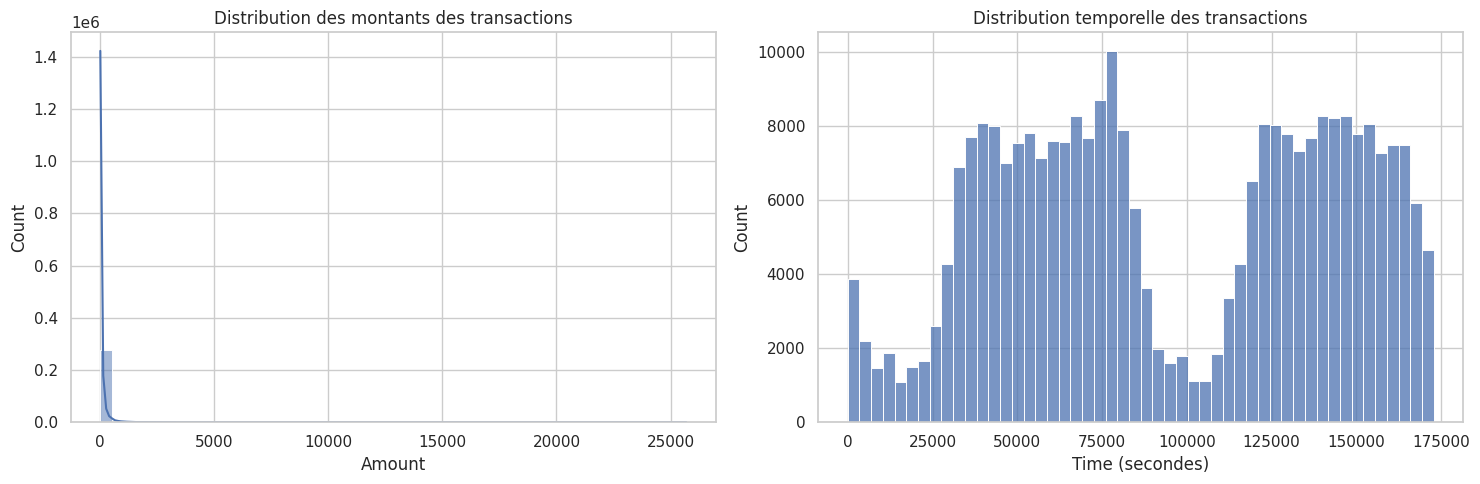

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Distribution des montants
sns.histplot(
    data=df_clean,
    x="Amount",
    bins=50,
    kde=True,
    ax=axes[0]
)
axes[0].set_title("Distribution des montants des transactions")
axes[0].set_xlabel("Amount")

# Distribution temporelle
sns.histplot(
    data=df_clean,
    x="Time",
    bins=50,
    ax=axes[1]
)
axes[1].set_title("Distribution temporelle des transactions")
axes[1].set_xlabel("Time (secondes)")

plt.tight_layout()
plt.show()

### Analyse des distributions de Time et Amount

L'analyse graphique de la variable `Amount` révèle une distribution fortement asymétrique à droite. La majorité des transactions concernent des montants relativement faibles, tandis qu'un nombre limité de transactions présente des montants très élevés.

Cette dispersion importante rend la visualisation des petites transactions difficile sur l'échelle initiale.

Concernant la variable `Time`, la distribution des transactions n'est pas uniforme. Deux périodes de forte activité sont visibles, séparées par une période durant laquelle le nombre de transactions diminue.

Ces observations montrent que les variables `Time` et `Amount` présentent des distributions différentes qui devront être prises en compte lors de la préparation des données.

Aucune transformation ni suppression de valeurs extrêmes n'est effectuée à ce stade.

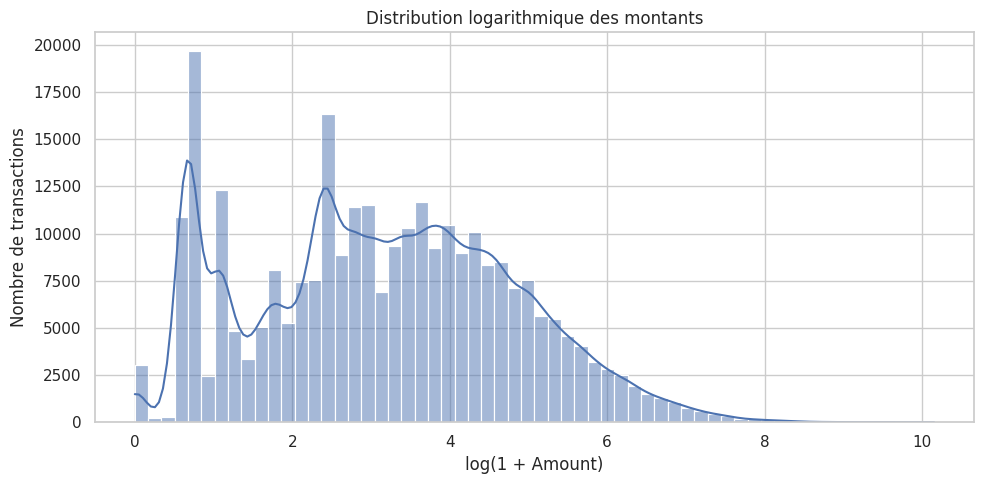

In [18]:
# Transformation logarithmique pour la visualisation uniquement
amount_log = np.log1p(df_clean["Amount"])

plt.figure(figsize=(10, 5))

sns.histplot(
    amount_log,
    bins=60,
    kde=True
)

plt.title("Distribution logarithmique des montants")
plt.xlabel("log(1 + Amount)")
plt.ylabel("Nombre de transactions")

plt.tight_layout()
plt.show()

### Analyse complémentaire de la variable Amount : transformation logarithmique

Afin de mieux examiner la distribution des montants, une transformation logarithmique utilisant la fonction log(1 + Amount) a été appliquée à des fins de visualisation.

Cette transformation permet de réduire l'influence visuelle des montants particulièrement élevés et de mieux observer la répartition des transactions de faible et moyen montant.

Le graphique obtenu révèle plusieurs concentrations de transactions ainsi qu'une asymétrie persistante vers les valeurs élevées.

Cette observation montre que la variable Amount présente une distribution particulière qui mérite une attention lors de la préparation des données.

À ce stade, la transformation est utilisée uniquement pour l'exploration graphique. Aucune modification n'a été apportée à la variable originale dans le dataset.

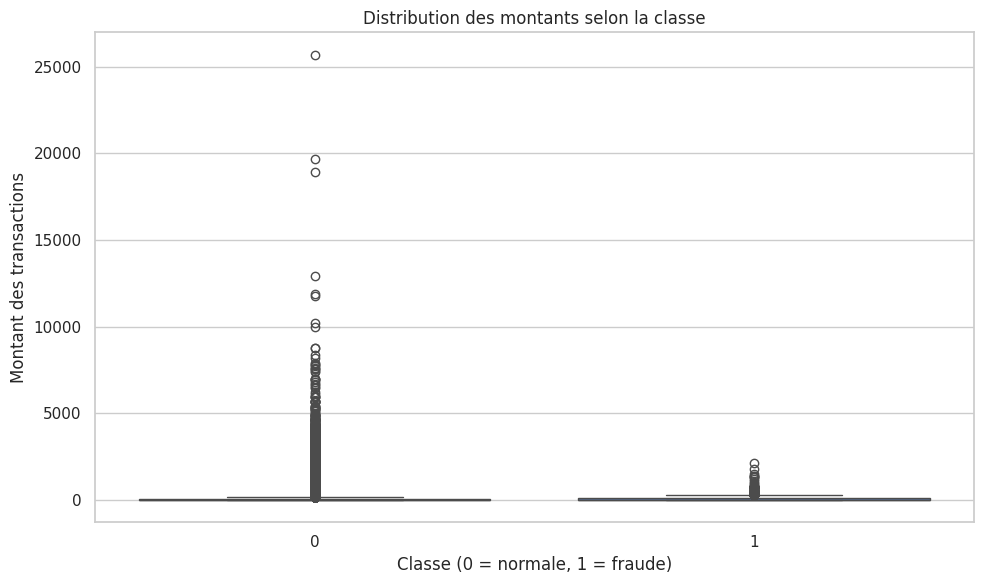

In [19]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df_clean,
    x="Class",
    y="Amount"
)

plt.title("Distribution des montants selon la classe")
plt.xlabel("Classe (0 = normale, 1 = fraude)")
plt.ylabel("Montant des transactions")

plt.tight_layout()
plt.show()

In [20]:
# Statistiques descriptives des montants par classe
stats_amount = df_clean.groupby("Class")["Amount"].describe()

display(stats_amount)

,count,mean,std,min,25%,50%,75%,max
Class,,,,,,,,
0,283253.0,88.413575,250.379023,0.0,5.67,22.00,77.46,25691.16
1,473.0,123.871860,260.211041,0.0,1.00,9.82,105.89,2125.87


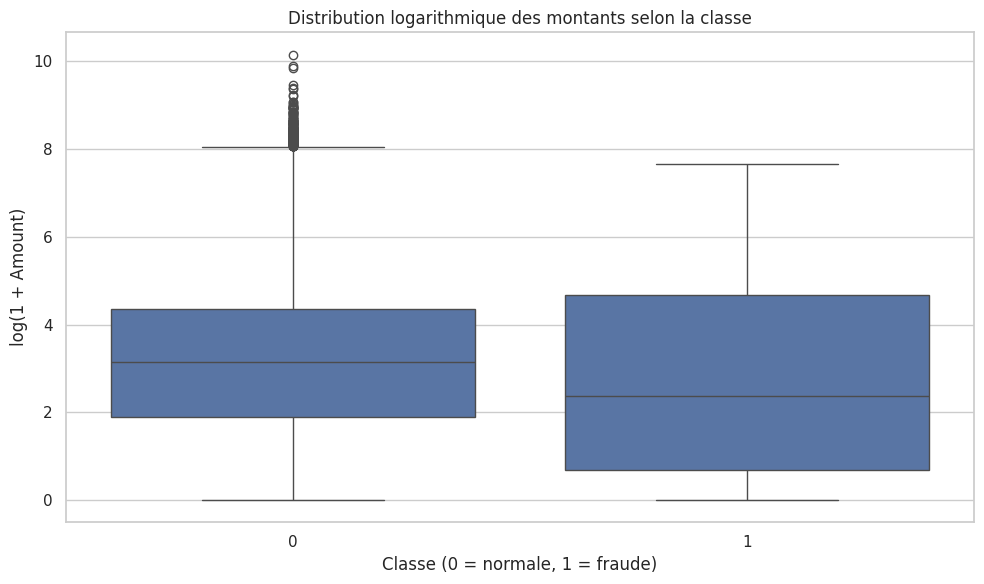

In [21]:
# Transformation temporaire pour la visualisation
df_plot = df_clean[["Amount", "Class"]].copy()

df_plot["Amount_log"] = np.log1p(df_plot["Amount"])

# Boxplot comparatif
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df_plot,
    x="Class",
    y="Amount_log"
)

plt.title("Distribution logarithmique des montants selon la classe")
plt.xlabel("Classe (0 = normale, 1 = fraude)")
plt.ylabel("log(1 + Amount)")

plt.tight_layout()
plt.show()

### Comparaison logarithmique des montants selon la classe

Afin de faciliter la comparaison des montants entre les deux catégories de transactions, une transformation logarithmique log(1 + Amount) a été appliquée uniquement pour la visualisation.

Le graphique montre que la médiane des transactions normales est supérieure à celle des transactions frauduleuses.

La distribution des montants frauduleux présente également une dispersion centrale plus importante sur l'échelle logarithmique.

Un chevauchement entre les deux distributions reste néanmoins visible. La variable Amount ne permet donc pas, à elle seule, de distinguer parfaitement les transactions normales des transactions frauduleuses.

Cette analyse confirme l'intérêt d'étudier conjointement plusieurs variables pour la détection des fraudes.

Aucune transformation permanente n'a été appliquée au dataset.

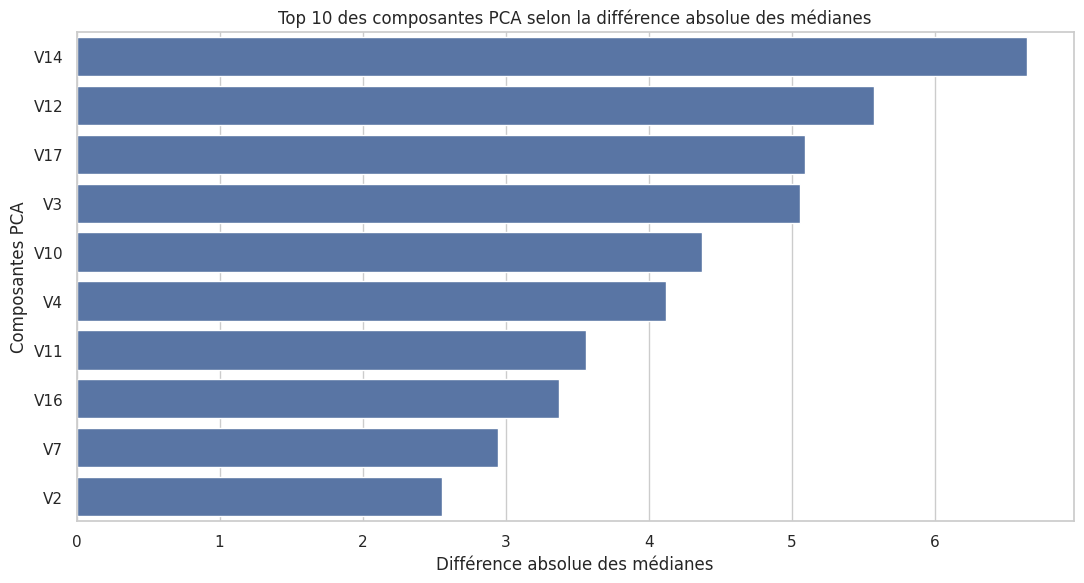

,Difference_absolue_medianes
V14,6.642036
V12,5.577926
V17,5.092500
V3,5.057644
V10,4.374164
V4,4.124598
V11,3.560172
V16,3.370998
V7,2.943743
V2,2.554544


In [22]:
# Calcul des médianes par classe pour les composantes PCA
pca_columns = [f"V{i}" for i in range(1, 29)]

median_by_class = df_clean.groupby("Class")[pca_columns].median()

# Différence absolue des médianes entre les deux classes
median_diff = (
    median_by_class.loc[1] - median_by_class.loc[0]
).abs().sort_values(ascending=False)

# Visualisation des 10 composantes présentant les plus grandes différences
plt.figure(figsize=(11, 6))

sns.barplot(
    x=median_diff.head(10).values,
    y=median_diff.head(10).index
)

plt.title("Top 10 des composantes PCA selon la différence absolue des médianes")
plt.xlabel("Différence absolue des médianes")
plt.ylabel("Composantes PCA")

plt.tight_layout()
plt.show()

display(median_diff.head(10).to_frame("Difference_absolue_medianes"))

### Analyse des différences de médianes des composantes PCA selon la classe

Afin d'identifier les composantes présentant des différences statistiques entre les transactions normales et frauduleuses, nous avons calculé les médianes de chaque variable PCA pour les deux classes.

La différence absolue entre les médianes a ensuite été calculée pour chaque composante.

Les résultats montrent que V14 présente la différence absolue de médianes la plus importante (6,6420), suivie de V12 (5,5779), V17 (5,0925) et V3 (5,0576).

Ces observations indiquent que certaines composantes PCA présentent des distributions centrales différentes selon la classe.

Cependant, la différence entre les médianes ne suffit pas à déterminer le pouvoir prédictif d'une variable. Une analyse complémentaire des distributions sera nécessaire.

Les composantes PCA restent anonymisées et aucune interprétation métier ne leur est attribuée.

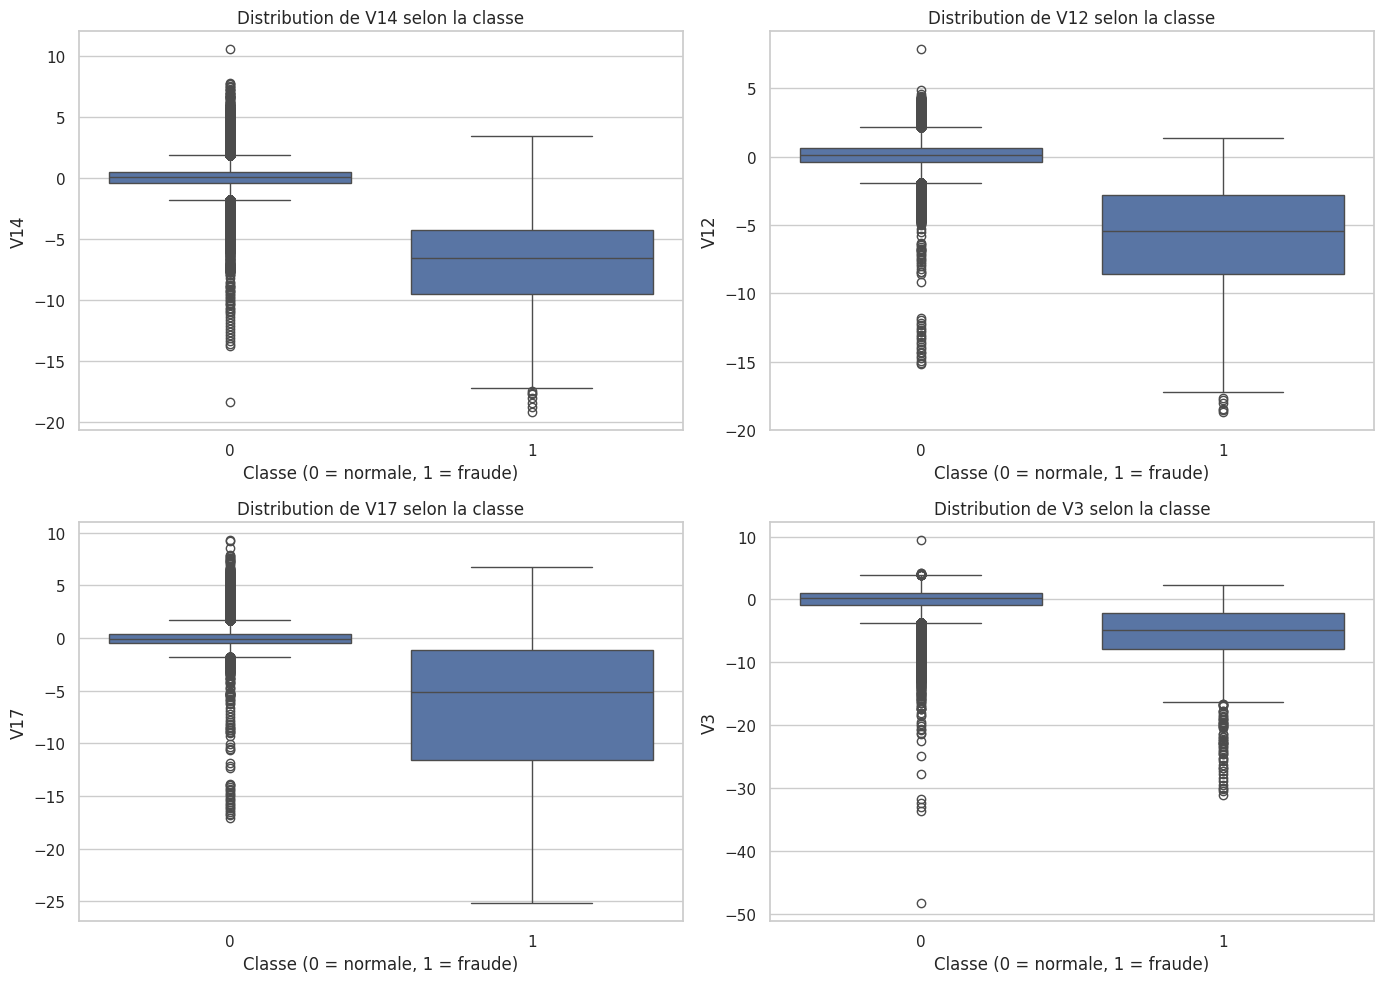

In [23]:
# Sélection des quatre composantes principales
top_features = ["V14", "V12", "V17", "V3"]

# Création de la figure
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

axes = axes.flatten()

for i, feature in enumerate(top_features):

    sns.boxplot(
        data=df_clean,
        x="Class",
        y=feature,
        ax=axes[i]
    )

    axes[i].set_title(
        f"Distribution de {feature} selon la classe"
    )

    axes[i].set_xlabel("Classe (0 = normale, 1 = fraude)")
    axes[i].set_ylabel(feature)

plt.tight_layout()
plt.show()

### Analyse des principales composantes PCA selon la classe

L'analyse des distributions de V14, V12, V17 et V3 révèle des différences visuelles importantes entre les transactions normales et frauduleuses.

La composante V14 présente notamment un décalage marqué entre les distributions des deux classes. Des différences sont également observées pour V12, V17 et V3.

Ces observations suggèrent que certaines composantes PCA contiennent des informations potentiellement utiles pour distinguer les transactions frauduleuses des transactions normales.

Cependant, cette analyse exploratoire ne permet pas à elle seule de mesurer leur pouvoir prédictif. Celui-ci sera évalué lors de l'entraînement et de l'évaluation des modèles.

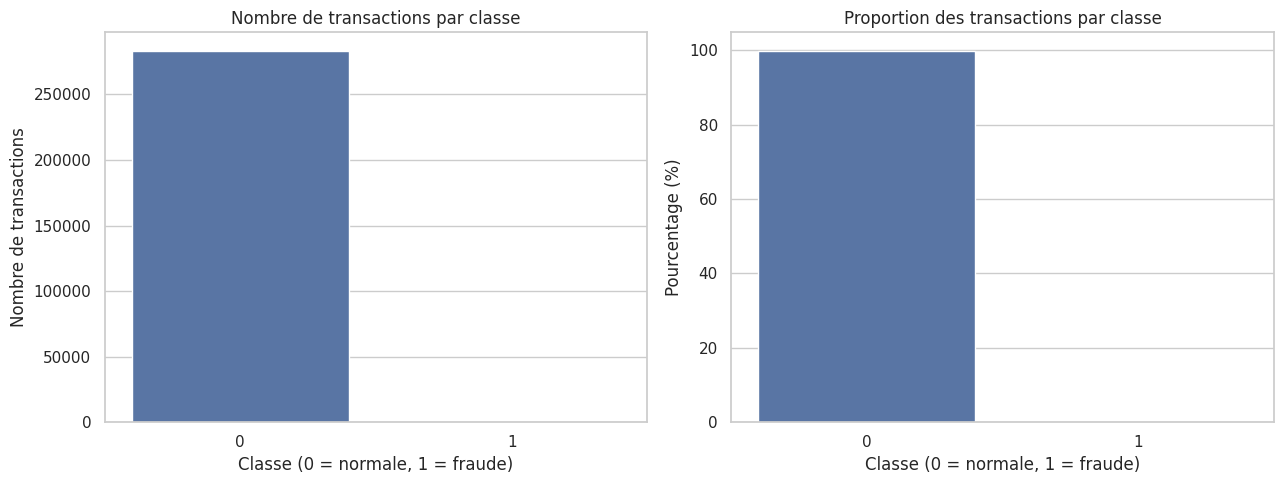

,Nombre,Pourcentage
Class,,
0,283253,99.83329
1,473,0.16671


In [24]:
# Calcul des effectifs et proportions
class_counts = df_clean["Class"].value_counts().sort_index()
class_percentages = df_clean["Class"].value_counts(normalize=True).sort_index() * 100

# Graphique
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.barplot(
    x=class_counts.index,
    y=class_counts.values,
    ax=axes[0]
)

axes[0].set_title("Nombre de transactions par classe")
axes[0].set_xlabel("Classe (0 = normale, 1 = fraude)")
axes[0].set_ylabel("Nombre de transactions")

sns.barplot(
    x=class_percentages.index,
    y=class_percentages.values,
    ax=axes[1]
)

axes[1].set_title("Proportion des transactions par classe")
axes[1].set_xlabel("Classe (0 = normale, 1 = fraude)")
axes[1].set_ylabel("Pourcentage (%)")

plt.tight_layout()
plt.show()

display(pd.DataFrame({
    "Nombre": class_counts,
    "Pourcentage": class_percentages
}))

### Analyse du déséquilibre des classes

L'analyse de la variable cible révèle un déséquilibre important entre les deux catégories de transactions.

Après nettoyage, le dataset contient 283 253 transactions normales, représentant 99,83329 % des observations, contre 473 transactions frauduleuses, représentant 0,16671 %.

Cela correspond approximativement à 599 transactions normales pour une transaction frauduleuse.

Ce déséquilibre constitue un défi majeur pour l'apprentissage automatique. Un modèle pourrait obtenir une accuracy élevée en prédisant principalement la classe majoritaire, sans être capable de détecter correctement les fraudes.

Par conséquent, l'évaluation reposera principalement sur Precision, Recall, F1-score et PR-AUC plutôt que sur l'accuracy seule.

In [25]:
# Vérification de l'ordre temporel
print("Première valeur de Time :", df_clean["Time"].min())
print("Dernière valeur de Time :", df_clean["Time"].max())

print(
    "Dataset déjà trié chronologiquement :",
    df_clean["Time"].is_monotonic_increasing
)

# Vérification du nombre de fraudes par période
print("\nNombre de fraudes par quartile temporel :")

df_temp = df_clean.copy()

df_temp["Periode"] = pd.qcut(
    df_temp["Time"],
    q=4,
    labels=["Q1", "Q2", "Q3", "Q4"]
)

display(
    df_temp.groupby("Periode", observed=False)["Class"]
    .agg(["count", "sum"])
)

Première valeur de Time : 0.0
Dernière valeur de Time : 172792.0
Dataset déjà trié chronologiquement : True

Nombre de fraudes par quartile temporel :


,count,sum
Periode,,
Q1,70932,177
Q2,70931,85
Q3,70932,118
Q4,70931,93


In [27]:
# Définition des seuils temporels
time_70 = df_clean["Time"].quantile(0.70)
time_85 = df_clean["Time"].quantile(0.85)

# Séparation chronologique
train_df = df_clean[df_clean["Time"] <= time_70].copy()

val_df = df_clean[
    (df_clean["Time"] > time_70) &
    (df_clean["Time"] <= time_85)
].copy()

test_df = df_clean[df_clean["Time"] > time_85].copy()

# Fonction de diagnostic
def inspect_split(name, data):
    print(f"\n--- {name} ---")
    print("Dimensions :", data.shape)
    print("Période :", data["Time"].min(), "à", data["Time"].max())
    print("Transactions normales :", (data["Class"] == 0).sum())
    print("Transactions frauduleuses :", (data["Class"] == 1).sum())
    print("Taux de fraude (%) :", round(data["Class"].mean() * 100, 5))

inspect_split("TRAIN", train_df)
inspect_split("VALIDATION", val_df)
inspect_split("TEST", test_df)


--- TRAIN ---
Dimensions : (198609, 31)
Période : 0.0 à 132906.0
Transactions normales : 198243
Transactions frauduleuses : 366
Taux de fraude (%) : 0.18428

--- VALIDATION ---
Dimensions : (42560, 31)
Période : 132907.0 à 151320.0
Transactions normales : 42505
Transactions frauduleuses : 55
Taux de fraude (%) : 0.12923

--- TEST ---
Dimensions : (42557, 31)
Période : 151321.0 à 172792.0
Transactions normales : 42505
Transactions frauduleuses : 52
Taux de fraude (%) : 0.12219


### Séparation chronologique des données

Afin d'éviter toute fuite temporelle, le dataset a été divisé chronologiquement en trois ensembles :

- Train : 70 % environ, utilisé pour l'apprentissage.
- Validation : 15 % environ, utilisé pour le réglage des modèles.
- Test : 15 % environ, réservé à l'évaluation finale.

La séparation conserve l'ordre temporel des transactions. Aucun mélange aléatoire n'a été effectué.

Les résultats montrent une diminution progressive du taux de fraude entre les ensembles Train (0,18428 %), Validation (0,12923 %) et Test (0,12219 %).

Cette variation est conservée afin de représenter les conditions temporelles observées dans le dataset.

Le jeu de test ne sera pas utilisé pour le réglage des hyperparamètres ni pour le choix des modèles.

In [28]:
# Séparation des variables explicatives et de la cible

X_train = train_df.drop(columns=["Class"])
y_train = train_df["Class"]

X_val = val_df.drop(columns=["Class"])
y_val = val_df["Class"]

X_test = test_df.drop(columns=["Class"])
y_test = test_df["Class"]

# Vérification
print("TRAIN :", X_train.shape, y_train.shape)
print("VALIDATION :", X_val.shape, y_val.shape)
print("TEST :", X_test.shape, y_test.shape)

# Vérification de la présence de la cible
assert "Class" not in X_train.columns
assert "Class" not in X_val.columns
assert "Class" not in X_test.columns

# Vérification des effectifs
assert y_train.sum() == 366
assert y_val.sum() == 55
assert y_test.sum() == 52

print("\nSéparation X/y validée.")

TRAIN : (198609, 30) (198609,)
VALIDATION : (42560, 30) (42560,)
TEST : (42557, 30) (42557,)

Séparation X/y validée.


,Model,Accuracy,Precision,Recall,F1-score,PR-AUC
0,Baseline,0.998708,0.0,0.0,0.0,0.001292


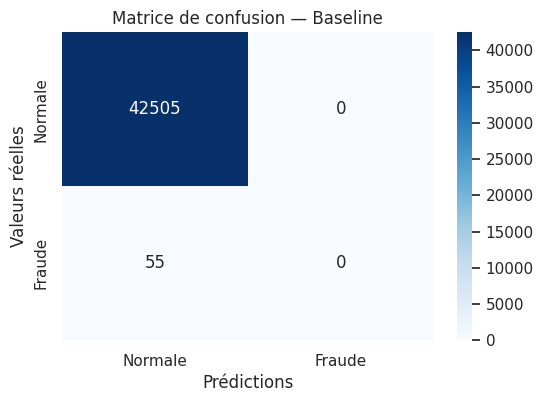

In [29]:
# ============================================
# SO6 — BASELINE
# ============================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

# Prédiction systématique de la classe majoritaire
y_val_baseline = np.zeros(len(y_val), dtype=int)

# Calcul des métriques sur la validation
baseline_results = {
    "Model": "Baseline",
    "Accuracy": accuracy_score(y_val, y_val_baseline),
    "Precision": precision_score(
        y_val, y_val_baseline, zero_division=0
    ),
    "Recall": recall_score(
        y_val, y_val_baseline, zero_division=0
    ),
    "F1-score": f1_score(
        y_val, y_val_baseline, zero_division=0
    ),
    "PR-AUC": average_precision_score(
        y_val, y_val_baseline
    )
}

# Affichage des résultats
baseline_df = pd.DataFrame([baseline_results])

display(baseline_df)

# Matrice de confusion
cm = confusion_matrix(y_val, y_val_baseline)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Normale", "Fraude"],
    yticklabels=["Normale", "Fraude"]
)

plt.title("Matrice de confusion — Baseline")
plt.xlabel("Prédictions")
plt.ylabel("Valeurs réelles")
plt.show()

,Model,Threshold,Accuracy,Precision,Recall,F1-score,PR-AUC
0,Logistic Regression,0.999995,0.999601,0.913043,0.763636,0.831683,0.83665


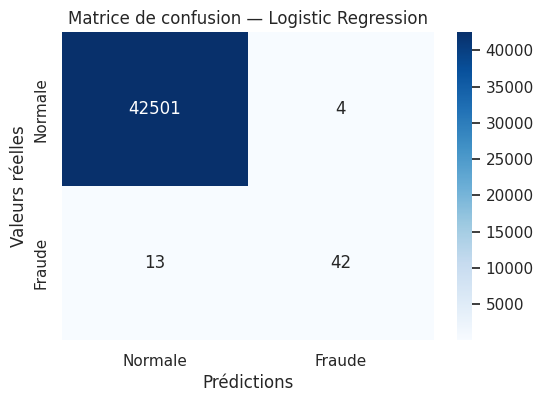

In [30]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    precision_recall_curve,
    average_precision_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# 1. Création du pipeline
lr_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=2000,
        random_state=RANDOM_STATE
    ))
])

# 2. Entraînement sur Train uniquement
lr_model.fit(X_train, y_train)

# 3. Probabilités prédites sur Validation
y_val_proba_lr = lr_model.predict_proba(X_val)[:, 1]

# 4. Recherche du seuil optimal sur Validation
precision_values, recall_values, thresholds = precision_recall_curve(
    y_val,
    y_val_proba_lr
)

f1_values = (
    2 * precision_values[:-1] * recall_values[:-1]
    / (precision_values[:-1] + recall_values[:-1] + 1e-12)
)

best_idx = np.argmax(f1_values)
best_threshold_lr = thresholds[best_idx]

# 5. Prédictions avec le seuil sélectionné
y_val_pred_lr = (
    y_val_proba_lr >= best_threshold_lr
).astype(int)

# 6. Évaluation
lr_results = {
    "Model": "Logistic Regression",
    "Threshold": best_threshold_lr,
    "Accuracy": accuracy_score(y_val, y_val_pred_lr),
    "Precision": precision_score(y_val, y_val_pred_lr, zero_division=0),
    "Recall": recall_score(y_val, y_val_pred_lr, zero_division=0),
    "F1-score": f1_score(y_val, y_val_pred_lr, zero_division=0),
    "PR-AUC": average_precision_score(y_val, y_val_proba_lr)
}

display(pd.DataFrame([lr_results]))

# 7. Matrice de confusion
cm_lr = confusion_matrix(y_val, y_val_pred_lr)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm_lr,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Normale", "Fraude"],
    yticklabels=["Normale", "Fraude"]
)

plt.title("Matrice de confusion — Logistic Regression")
plt.xlabel("Prédictions")
plt.ylabel("Valeurs réelles")
plt.show()

### Résultats de Logistic Regression

Le modèle Logistic Regression a été entraîné sur l'ensemble Train avec une standardisation des variables et une pondération des classes (`class_weight="balanced"`).

Le seuil de classification a été sélectionné sur l'ensemble Validation en maximisant le F1-score. Le seuil obtenu est de 0,999995.

Les résultats obtenus sur Validation sont les suivants :

- Accuracy : 99,9601 %
- Precision : 91,3043 %
- Recall : 76,3636 %
- F1-score : 83,1683 %
- PR-AUC (Average Precision) : 83,665 %

La matrice de confusion indique que 42 transactions frauduleuses sur 55 ont été détectées, tandis que 13 ont été manquées. Quatre transactions normales ont été incorrectement classées comme frauduleuses.

Ces résultats montrent une amélioration importante par rapport à la baseline. Le modèle parvient à détecter une proportion importante de fraudes tout en maintenant un nombre limité de fausses alertes.

Les résultats restent des performances de validation et devront être confirmés lors de l'évaluation finale sur le jeu de test.

,Model,Threshold,Accuracy,Precision,Recall,F1-score,PR-AUC
0,Random Forest,0.354681,0.999718,1.0,0.781818,0.877551,0.875029


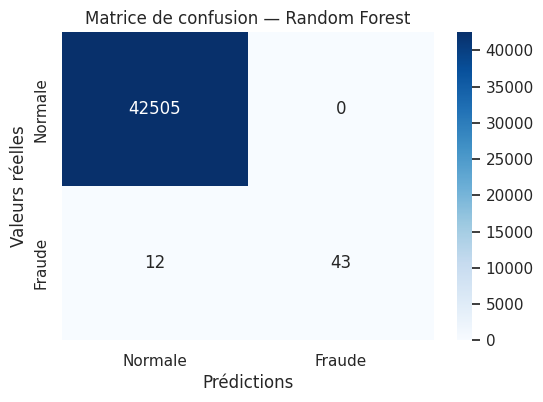

In [32]:
from sklearn.ensemble import RandomForestClassifier

# 1. Initialisation du modèle
rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=None,
    min_samples_leaf=2,
    class_weight="balanced_subsample",
    random_state=RANDOM_STATE,
    n_jobs=-1
)

# 2. Entraînement exclusivement sur Train
rf_model.fit(X_train, y_train)

# 3. Probabilités sur Validation
y_val_proba_rf = rf_model.predict_proba(X_val)[:, 1]

# 4. Recherche du meilleur seuil sur Validation
precision_rf, recall_rf, thresholds_rf = precision_recall_curve(
    y_val,
    y_val_proba_rf
)

f1_rf = (
    2 * precision_rf[:-1] * recall_rf[:-1]
    / (precision_rf[:-1] + recall_rf[:-1] + 1e-12)
)

best_idx_rf = np.argmax(f1_rf)
best_threshold_rf = thresholds_rf[best_idx_rf]

# 5. Prédictions
y_val_pred_rf = (
    y_val_proba_rf >= best_threshold_rf
).astype(int)

# 6. Évaluation
rf_results = {
    "Model": "Random Forest",
    "Threshold": best_threshold_rf,
    "Accuracy": accuracy_score(y_val, y_val_pred_rf),
    "Precision": precision_score(y_val, y_val_pred_rf, zero_division=0),
    "Recall": recall_score(y_val, y_val_pred_rf, zero_division=0),
    "F1-score": f1_score(y_val, y_val_pred_rf, zero_division=0),
    "PR-AUC": average_precision_score(y_val, y_val_proba_rf)
}

display(pd.DataFrame([rf_results]))

# 7. Matrice de confusion
cm_rf = confusion_matrix(y_val, y_val_pred_rf)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm_rf,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Normale", "Fraude"],
    yticklabels=["Normale", "Fraude"]
)

plt.title("Matrice de confusion — Random Forest")
plt.xlabel("Prédictions")
plt.ylabel("Valeurs réelles")
plt.show()

### Résultats de Random Forest

Le modèle Random Forest a été entraîné sur l'ensemble Train avec une pondération des classes utilisant le paramètre `balanced_subsample`.

Le seuil de classification a été sélectionné sur l'ensemble Validation en maximisant le F1-score. Le seuil obtenu est de 0,354681.

Les résultats obtenus sont :

- Accuracy : 99,9718 %
- Precision : 100 %
- Recall : 78,1818 %
- F1-score : 87,7551 %
- PR-AUC (Average Precision) : 87,5029 %

La matrice de confusion montre que 43 transactions frauduleuses sur 55 ont été correctement détectées. Les 12 autres ont été classées comme normales. Aucune fausse alerte n'a été observée.

Comparativement à Logistic Regression, Random Forest présente une meilleure précision, un meilleur rappel, un meilleur F1-score et une meilleure PR-AUC sur l'ensemble de validation.

Il constitue donc le meilleur modèle supervisé parmi les deux approches évaluées jusqu'à présent.

,Model,Threshold,Accuracy,Precision,Recall,F1-score,PR-AUC
0,Isolation Forest,0.063826,0.984211,0.044313,0.545455,0.081967,0.03197


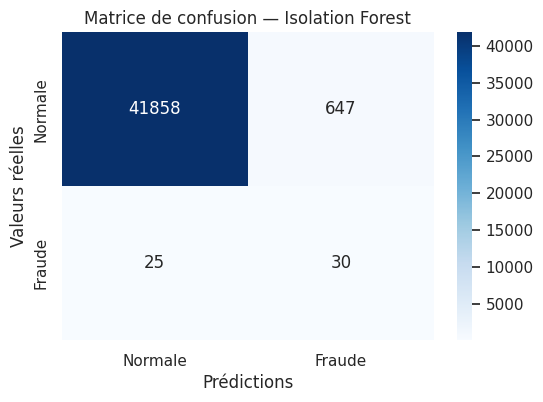

In [33]:
from sklearn.ensemble import IsolationForest

# 1. Initialisation
if_model = IsolationForest(
    n_estimators=200,
    max_samples="auto",
    contamination="auto",
    random_state=RANDOM_STATE,
    n_jobs=-1
)

# 2. Apprentissage non supervisé
if_model.fit(X_train)

# 3. Scores d'anomalie sur Validation
# Plus le score est élevé, plus l'observation est suspecte.
y_val_scores_if = -if_model.decision_function(X_val)

# 4. Recherche du seuil optimal sur Validation
precision_if, recall_if, thresholds_if = precision_recall_curve(
    y_val,
    y_val_scores_if
)

f1_if = (
    2 * precision_if[:-1] * recall_if[:-1]
    / (precision_if[:-1] + recall_if[:-1] + 1e-12)
)

best_idx_if = np.argmax(f1_if)
best_threshold_if = thresholds_if[best_idx_if]

# 5. Prédictions
y_val_pred_if = (
    y_val_scores_if >= best_threshold_if
).astype(int)

# 6. Évaluation
if_results = {
    "Model": "Isolation Forest",
    "Threshold": best_threshold_if,
    "Accuracy": accuracy_score(y_val, y_val_pred_if),
    "Precision": precision_score(y_val, y_val_pred_if, zero_division=0),
    "Recall": recall_score(y_val, y_val_pred_if, zero_division=0),
    "F1-score": f1_score(y_val, y_val_pred_if, zero_division=0),
    "PR-AUC": average_precision_score(y_val, y_val_scores_if)
}

display(pd.DataFrame([if_results]))

# 7. Matrice de confusion
cm_if = confusion_matrix(y_val, y_val_pred_if)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm_if,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Normale", "Fraude"],
    yticklabels=["Normale", "Fraude"]
)

plt.title("Matrice de confusion — Isolation Forest")
plt.xlabel("Prédictions")
plt.ylabel("Valeurs réelles")
plt.show()

### Résultats d'Isolation Forest

Isolation Forest a été entraîné de manière non supervisée sur l'ensemble Train, sans utiliser les étiquettes de classe.

Le seuil de détection a été sélectionné sur Validation en maximisant le F1-score. Le seuil obtenu est de 0,063826.

Les résultats obtenus sont :

- Accuracy : 98,4211 %
- Precision : 4,4313 %
- Recall : 54,5455 %
- F1-score : 8,1967 %
- PR-AUC (Average Precision) : 3,197 %

La matrice de confusion indique que 30 transactions frauduleuses sur 55 ont été détectées, tandis que 25 ont été manquées. Cependant, 647 transactions normales ont été incorrectement signalées comme frauduleuses.

Ces résultats montrent qu'Isolation Forest détecte une partie des anomalies, mais présente un nombre élevé de fausses alertes.

Sur cet ensemble de validation, ses performances sont nettement inférieures à celles des deux modèles supervisés.

In [35]:
from pathlib import Path

# Regroupement des résultats des quatre approches
results_df = pd.DataFrame([
    baseline_results,
    lr_results,
    rf_results,
    if_results
])

# Organisation des colonnes
results_df = results_df[
    [
        "Model",
        "Threshold",
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score",
        "PR-AUC"
    ]
]

# Création du dossier results
Path("results").mkdir(exist_ok=True)

# Export CSV
results_df.to_csv(
    "results/resultats.csv",
    index=False
)

display(results_df)

print("Résultats sauvegardés dans results/resultats.csv")

,Model,Threshold,Accuracy,Precision,Recall,F1-score,PR-AUC
0,Baseline,NaN,0.998708,0.000000,0.000000,0.000000,0.001292
1,Logistic Regression,0.999995,0.999601,0.913043,0.763636,0.831683,0.836650
2,Random Forest,0.354681,0.999718,1.000000,0.781818,0.877551,0.875029
3,Isolation Forest,0.063826,0.984211,0.044313,0.545455,0.081967,0.031970


Résultats sauvegardés dans results/resultats.csv


In [36]:
final_configurations = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "Parameters": "C=1, class_weight=balanced, max_iter=2000",
        "Threshold": best_threshold_lr
    },
    {
        "Model": "Random Forest",
        "Parameters": "n_estimators=200, max_depth=None, min_samples_leaf=2, class_weight=balanced_subsample",
        "Threshold": best_threshold_rf
    },
    {
        "Model": "Isolation Forest",
        "Parameters": "n_estimators=200, max_samples=auto, contamination=auto",
        "Threshold": best_threshold_if
    }
])

display(final_configurations)

final_configurations.to_csv(
    "results/configurations.csv",
    index=False
)

print("Configurations enregistrées.")

,Model,Parameters,Threshold
0,Logistic Regression,"C=1, class_weight=balanced, max_iter=2000",0.999995
1,Random Forest,"n_estimators=200, max_depth=None, min_samples_...",0.354681
2,Isolation Forest,"n_estimators=200, max_samples=auto, contaminat...",0.063826


Configurations enregistrées.


In [37]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    confusion_matrix
)

# ==========================================
# 1. PRÉDICTIONS SUR LE TEST
# ==========================================

# Logistic Regression
y_test_proba_lr = lr_model.predict_proba(X_test)[:, 1]

y_test_pred_lr = (
    y_test_proba_lr >= best_threshold_lr
).astype(int)

# Random Forest
y_test_proba_rf = rf_model.predict_proba(X_test)[:, 1]

y_test_pred_rf = (
    y_test_proba_rf >= best_threshold_rf
).astype(int)

# Isolation Forest
y_test_scores_if = -if_model.decision_function(X_test)

y_test_pred_if = (
    y_test_scores_if >= best_threshold_if
).astype(int)

# Baseline
y_test_pred_baseline = np.zeros(len(y_test), dtype=int)
y_test_scores_baseline = np.zeros(len(y_test))


# ==========================================
# 2. FONCTION D'ÉVALUATION
# ==========================================

def evaluate_model(name, y_true, y_pred, scores, threshold):

    return {
        "Model": name,
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(
            y_true, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_true, y_pred, zero_division=0
        ),
        "F1-score": f1_score(
            y_true, y_pred, zero_division=0
        ),
        "PR-AUC": average_precision_score(
            y_true, scores
        )
    }


# ==========================================
# 3. RÉSULTATS FINAUX
# ==========================================

test_results = pd.DataFrame([

    evaluate_model(
        "Baseline",
        y_test,
        y_test_pred_baseline,
        y_test_scores_baseline,
        np.nan
    ),

    evaluate_model(
        "Logistic Regression",
        y_test,
        y_test_pred_lr,
        y_test_proba_lr,
        best_threshold_lr
    ),

    evaluate_model(
        "Random Forest",
        y_test,
        y_test_pred_rf,
        y_test_proba_rf,
        best_threshold_rf
    ),

    evaluate_model(
        "Isolation Forest",
        y_test,
        y_test_pred_if,
        y_test_scores_if,
        best_threshold_if
    )

])

display(test_results.round(6))


# ==========================================
# 4. SAUVEGARDE
# ==========================================

Path("results").mkdir(exist_ok=True)

test_results.to_csv(
    "results/resultats_test.csv",
    index=False
)

print("Évaluation finale enregistrée.")

,Model,Threshold,Accuracy,Precision,Recall,F1-score,PR-AUC
0,Baseline,NaN,0.998778,0.000000,0.000000,0.000000,0.001222
1,Logistic Regression,0.999995,0.999507,0.942857,0.634615,0.758621,0.710117
2,Random Forest,0.354681,0.999601,0.906977,0.750000,0.821053,0.771414
3,Isolation Forest,0.063826,0.989684,0.061224,0.519231,0.109533,0.040327


Évaluation finale enregistrée.


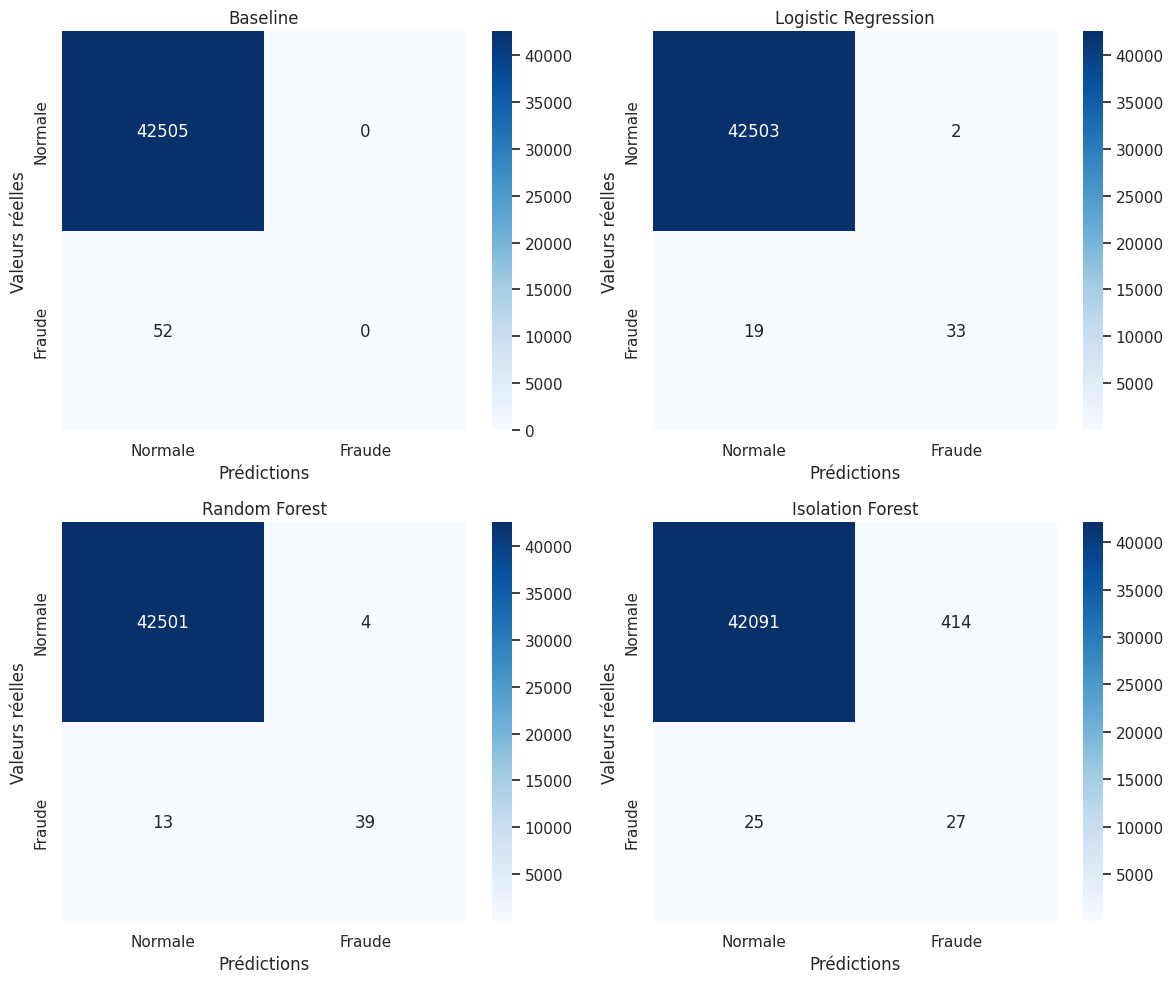

In [38]:
predictions = {
    "Baseline": y_test_pred_baseline,
    "Logistic Regression": y_test_pred_lr,
    "Random Forest": y_test_pred_rf,
    "Isolation Forest": y_test_pred_if
}

fig, axes = plt.subplots(2, 2, figsize=(12, 10))

for ax, (name, predictions_model) in zip(
    axes.flatten(), predictions.items()
):

    cm = confusion_matrix(y_test, predictions_model)

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Normale", "Fraude"],
        yticklabels=["Normale", "Fraude"],
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Prédictions")
    ax.set_ylabel("Valeurs réelles")

plt.tight_layout()
plt.show()

In [39]:
# ==========================================
# BOOTSTRAP — 1000 RÉÉCHANTILLONNAGES
# ==========================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score
)

N_BOOTSTRAP = 1000
BOOTSTRAP_SEED = 42

y_true = np.asarray(y_test)

models_data = {
    "Logistic Regression": (y_test_pred_lr, y_test_proba_lr),
    "Random Forest": (y_test_pred_rf, y_test_proba_rf),
    "Isolation Forest": (y_test_pred_if, y_test_scores_if),
    "Baseline": (y_test_pred_baseline, y_test_scores_baseline)
}

# Indices des deux classes
idx_normal = np.where(y_true == 0)[0]
idx_fraud = np.where(y_true == 1)[0]

rng = np.random.default_rng(BOOTSTRAP_SEED)

bootstrap_results = []

for model_name, (predictions, scores) in models_data.items():

    metrics_bootstrap = {
        "Accuracy": [],
        "Precision": [],
        "Recall": [],
        "F1-score": [],
        "PR-AUC": []
    }

    predictions = np.asarray(predictions)
    scores = np.asarray(scores)

    for _ in range(N_BOOTSTRAP):

        # Rééchantillonnage stratifié
        sample_normal = rng.choice(
            idx_normal,
            size=len(idx_normal),
            replace=True
        )

        sample_fraud = rng.choice(
            idx_fraud,
            size=len(idx_fraud),
            replace=True
        )

        sample_idx = np.concatenate([
            sample_normal,
            sample_fraud
        ])

        yt = y_true[sample_idx]
        yp = predictions[sample_idx]
        ys = scores[sample_idx]

        metrics_bootstrap["Accuracy"].append(
            accuracy_score(yt, yp)
        )

        metrics_bootstrap["Precision"].append(
            precision_score(yt, yp, zero_division=0)
        )

        metrics_bootstrap["Recall"].append(
            recall_score(yt, yp, zero_division=0)
        )

        metrics_bootstrap["F1-score"].append(
            f1_score(yt, yp, zero_division=0)
        )

        metrics_bootstrap["PR-AUC"].append(
            average_precision_score(yt, ys)
        )

    # Calcul des intervalles de confiance à 95 %
    for metric, values in metrics_bootstrap.items():

        lower = np.percentile(values, 2.5)
        upper = np.percentile(values, 97.5)

        bootstrap_results.append({
            "Model": model_name,
            "Metric": metric,
            "CI_lower": lower,
            "CI_upper": upper
        })

bootstrap_df = pd.DataFrame(bootstrap_results)

display(bootstrap_df.round(6))

# Sauvegarde
Path("results").mkdir(exist_ok=True)

bootstrap_df.to_csv(
    "results/bootstrap_intervals.csv",
    index=False
)

print("Intervalles de confiance sauvegardés.")

,Model,Metric,CI_lower,CI_upper
0,Logistic Regression,Accuracy,0.999342,0.999671
1,Logistic Regression,Precision,0.866667,1.000000
2,Logistic Regression,Recall,0.500000,0.750000
3,Logistic Regression,F1-score,0.658228,0.847826
4,Logistic Regression,PR-AUC,0.577530,0.847461
5,Random Forest,Accuracy,0.999436,0.999765
6,Random Forest,Precision,0.818182,0.976190
7,Random Forest,Recall,0.634615,0.865385
8,Random Forest,F1-score,0.734660,0.897959
9,Random Forest,PR-AUC,0.655960,0.872521


Intervalles de confiance sauvegardés.


In [40]:
# ==========================================
# COMPARAISON STATISTIQUE APPARIÉE
# Random Forest vs Logistic Regression
# ==========================================

N_BOOTSTRAP = 1000
rng = np.random.default_rng(42)

y_true = np.asarray(y_test)

# Indices des classes
idx_normal = np.where(y_true == 0)[0]
idx_fraud = np.where(y_true == 1)[0]

# Résultats des deux modèles
pred_lr = np.asarray(y_test_pred_lr)
pred_rf = np.asarray(y_test_pred_rf)

score_lr = np.asarray(y_test_proba_lr)
score_rf = np.asarray(y_test_proba_rf)

metrics_comparison = {
    "Precision": [],
    "Recall": [],
    "F1-score": [],
    "PR-AUC": []
}

# Bootstrap apparié
for _ in range(N_BOOTSTRAP):

    sample_normal = rng.choice(
        idx_normal,
        size=len(idx_normal),
        replace=True
    )

    sample_fraud = rng.choice(
        idx_fraud,
        size=len(idx_fraud),
        replace=True
    )

    sample_idx = np.concatenate([
        sample_normal,
        sample_fraud
    ])

    yt = y_true[sample_idx]

    # Prédictions des deux modèles sur les mêmes observations
    lr_pred = pred_lr[sample_idx]
    rf_pred = pred_rf[sample_idx]

    lr_score = score_lr[sample_idx]
    rf_score = score_rf[sample_idx]

    # Différences RF - LR
    metrics_comparison["Precision"].append(
        precision_score(yt, rf_pred, zero_division=0)
        - precision_score(yt, lr_pred, zero_division=0)
    )

    metrics_comparison["Recall"].append(
        recall_score(yt, rf_pred, zero_division=0)
        - recall_score(yt, lr_pred, zero_division=0)
    )

    metrics_comparison["F1-score"].append(
        f1_score(yt, rf_pred, zero_division=0)
        - f1_score(yt, lr_pred, zero_division=0)
    )

    metrics_comparison["PR-AUC"].append(
        average_precision_score(yt, rf_score)
        - average_precision_score(yt, lr_score)
    )


# Calcul des intervalles et des probabilités empiriques
comparison_results = []

for metric, differences in metrics_comparison.items():

    differences = np.asarray(differences)

    lower = np.percentile(differences, 2.5)
    upper = np.percentile(differences, 97.5)

    p_value = min(
        1.0,
        2 * min(
            (np.sum(differences <= 0) + 1) / (N_BOOTSTRAP + 1),
            (np.sum(differences >= 0) + 1) / (N_BOOTSTRAP + 1)
        )
    )

    comparison_results.append({
        "Metric": metric,
        "Mean_difference_RF_minus_LR": differences.mean(),
        "CI_lower": lower,
        "CI_upper": upper,
        "Bootstrap_p_value": p_value
    })

comparison_df = pd.DataFrame(comparison_results)

display(comparison_df.round(6))

# Sauvegarde
comparison_df.to_csv(
    "results/comparaison_statistique.csv",
    index=False
)

print("Comparaison statistique sauvegardée.")

,Metric,Mean_difference_RF_minus_LR,CI_lower,CI_upper,Bootstrap_p_value
0,Precision,-0.036393,-0.139409,0.065534,0.543457
1,Recall,0.114404,0.038462,0.211538,0.001998
2,F1-score,0.061769,-0.005938,0.137459,0.077922
3,PR-AUC,0.056428,-0.009163,0.147897,0.203796


Comparaison statistique sauvegardée.


========== RÉPARTITION DES PRÉDICTIONS ==========


,Nombre
Error_Type,
True Negative,42501
True Positive,39
False Negative,13
False Positive,4



========== NOMBRE TOTAL D'ERREURS ==========
Nombre d'erreurs : 17

========== STATISTIQUES DES ERREURS ==========


Amount                                Time            \
                      mean median  min      max           mean    median   
Error_Type                                                                 
False Negative  182.492308  12.31  0.0  1096.99  160020.923077  156710.0   
False Positive    1.745000   1.99  1.0     2.00  167401.750000  167836.0   

                                   Fraud_Probability                      \
                     min       max              mean    median       min   
Error_Type                                                                 
False Negative  152710.0  170348.0          0.011142  0.004983  0.000000   
False Positive  166023.0  167912.0          0.474655  0.434712  0.389565   

                          
                     max  
Error_Type                
False Negative  0.044942  
False Positive  0.639629

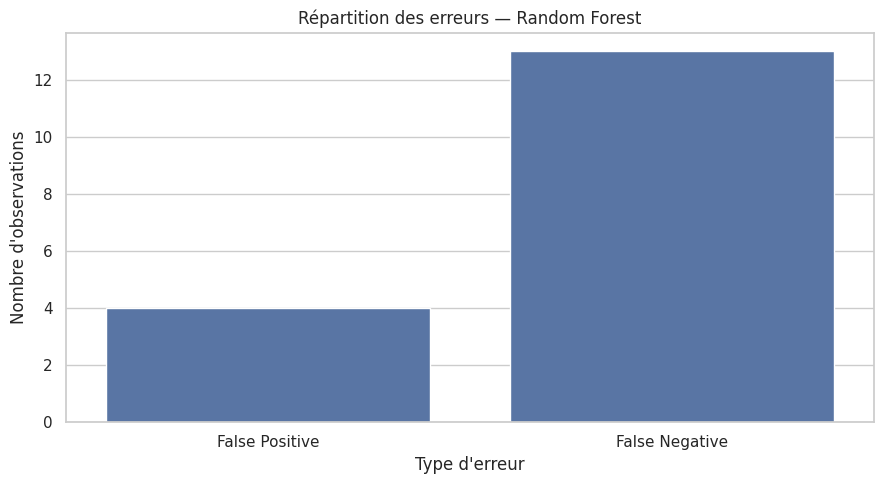

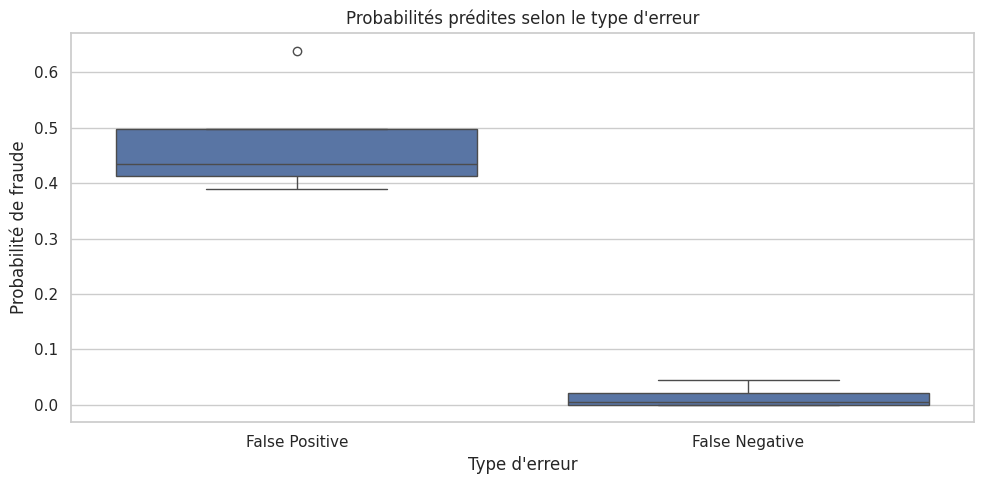


Analyse des erreurs sauvegardée avec succès.


In [43]:
# =====================================================
# ANALYSE DES ERREURS — RANDOM FOREST
# Évaluation sur le jeu de TEST
# =====================================================

# 1. Création d'une copie du jeu de test
error_df = test_df.copy()

# 2. Ajout des valeurs réelles et des prédictions
error_df["Actual"] = np.asarray(y_test)
error_df["Predicted"] = np.asarray(y_test_pred_rf)

error_df["Fraud_Probability"] = np.asarray(
    y_test_proba_rf
)

# 3. Identification des différents types de prédictions

conditions = [
    (error_df["Actual"] == 1) & (error_df["Predicted"] == 1),

    (error_df["Actual"] == 0) & (error_df["Predicted"] == 0),

    (error_df["Actual"] == 0) & (error_df["Predicted"] == 1),

    (error_df["Actual"] == 1) & (error_df["Predicted"] == 0)
]

labels = [
    "True Positive",
    "True Negative",
    "False Positive",
    "False Negative"
]

error_df["Error_Type"] = np.select(
    conditions,
    labels,
    default="Unknown"
)

# 4. Répartition des prédictions

print("========== RÉPARTITION DES PRÉDICTIONS ==========")

display(
    error_df["Error_Type"]
    .value_counts()
    .to_frame("Nombre")
)

# 5. Extraction des erreurs uniquement

errors = error_df[
    error_df["Error_Type"].isin([
        "False Positive",
        "False Negative"
    ])
].copy()

print("\n========== NOMBRE TOTAL D'ERREURS ==========")

print("Nombre d'erreurs :", len(errors))

# 6. Statistiques descriptives des erreurs

print("\n========== STATISTIQUES DES ERREURS ==========")

error_statistics = errors.groupby("Error_Type")[
    ["Amount", "Time", "Fraud_Probability"]
].agg([
    "mean",
    "median",
    "min",
    "max"
])

display(error_statistics)

# 7. Visualisation de la répartition des erreurs

plt.figure(figsize=(9, 5))

sns.countplot(
    data=errors,
    x="Error_Type",
    order=[
        "False Positive",
        "False Negative"
    ]
)

plt.title("Répartition des erreurs — Random Forest")
plt.xlabel("Type d'erreur")
plt.ylabel("Nombre d'observations")

plt.tight_layout()
plt.show()

# 8. Distribution des probabilités des erreurs

plt.figure(figsize=(10, 5))

sns.boxplot(
    data=errors,
    x="Error_Type",
    y="Fraud_Probability",
    order=[
        "False Positive",
        "False Negative"
    ]
)

plt.title("Probabilités prédites selon le type d'erreur")
plt.xlabel("Type d'erreur")
plt.ylabel("Probabilité de fraude")

plt.tight_layout()
plt.show()

# 9. Sauvegarde des résultats

Path("results").mkdir(exist_ok=True)

errors.to_csv(
    "results/random_forest_errors.csv",
    index=False
)

error_statistics.to_csv(
    "results/random_forest_error_statistics.csv"
)

print("\nAnalyse des erreurs sauvegardée avec succès.")

### Analyse des erreurs de Random Forest

L'analyse des erreurs sur le jeu de test révèle 17 erreurs de classification : 13 faux négatifs (False Negatives) et 4 faux positifs (False Positives).

Les faux négatifs correspondent aux transactions frauduleuses classées comme normales. Leur montant moyen est de 182,49, tandis que leur montant médian est de 12,31.

Les faux positifs correspondent aux transactions normales classées comme frauduleuses. Leur montant moyen est de 1,75 et leur montant médian est de 1,99.

L'analyse des probabilités montre que les faux négatifs présentent une probabilité moyenne de fraude de 0,01114, largement inférieure au seuil de classification de 0,354681. À l'inverse, les faux positifs présentent une probabilité moyenne de 0,47466.

Ces observations montrent que le modèle attribue des scores de fraude très faibles à certaines transactions frauduleuses, ce qui explique leur mauvaise classification.

Ces résultats restent descriptifs compte tenu du faible nombre d'erreurs observées.

,Feature,Importance_Mean,Importance_Std
4,V4,0.034994,0.001213
14,V14,0.032420,0.003056
16,V16,0.010716,0.001444
10,V10,0.010183,0.006830
12,V12,0.008889,0.004020
11,V11,0.008881,0.004550
28,V28,0.007894,0.006647
19,V19,0.007417,0.001826
17,V17,0.006829,0.001206
21,V21,0.006504,0.000822


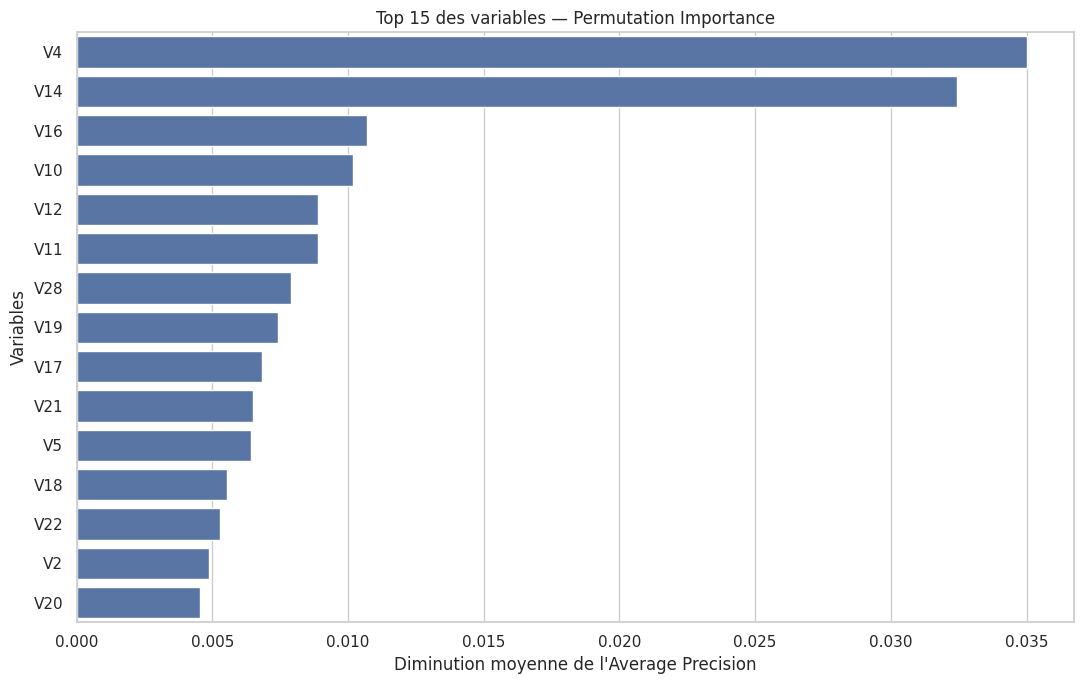

Importance des variables sauvegardée.


In [44]:
# =====================================================
# IMPORTANCE DES VARIABLES — RANDOM FOREST
# Permutation Importance sur Validation
# =====================================================

from sklearn.inspection import permutation_importance

# Calcul de l'importance des variables
perm_importance = permutation_importance(
    rf_model,
    X_val,
    y_val,
    scoring="average_precision",
    n_repeats=10,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

# Création du tableau
importance_df = pd.DataFrame({
    "Feature": X_val.columns,
    "Importance_Mean": perm_importance.importances_mean,
    "Importance_Std": perm_importance.importances_std
})

# Classement décroissant
importance_df = importance_df.sort_values(
    by="Importance_Mean",
    ascending=False
)

# Affichage des 15 variables les plus importantes
display(importance_df.head(15))

# Visualisation
plt.figure(figsize=(11, 7))

sns.barplot(
    data=importance_df.head(15),
    x="Importance_Mean",
    y="Feature"
)

plt.title("Top 15 des variables — Permutation Importance")
plt.xlabel("Diminution moyenne de l'Average Precision")
plt.ylabel("Variables")

plt.tight_layout()
plt.show()

# Sauvegarde
Path("results").mkdir(exist_ok=True)

importance_df.to_csv(
    "results/feature_importance_random_forest.csv",
    index=False
)

print("Importance des variables sauvegardée.")

### Analyse de l'importance des variables — Random Forest

Afin d'identifier les variables contribuant le plus aux performances de Random Forest, nous avons utilisé la méthode Permutation Importance.

Cette analyse a été réalisée sur l'ensemble de validation avec l'Average Precision comme métrique de référence.

Le principe consiste à mélanger successivement les valeurs d'une variable et à mesurer la diminution des performances du modèle.

Les résultats montrent que V4 (0,034994) et V14 (0,032420) présentent les importances moyennes les plus élevées.

Elles sont suivies notamment par V16, V10, V12 et V11.

Ces résultats indiquent que certaines composantes PCA jouent un rôle particulièrement important dans les capacités prédictives du modèle.

Il convient toutefois de rappeler que les variables V1 à V28 sont anonymisées et ne possèdent pas de signification métier directement interprétable dans le dataset.

Cette analyse permet d'identifier les variables les plus utiles à la prédiction, sans établir de relation causale.